In [ ]:
# ============================================================
# CELL 1: INSTALL AND IMPORT LIBRARIES
# ============================================================

!pip -q install scikit-learn pandas numpy matplotlib seaborn

import os
import zipfile
import warnings
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

np.random.seed(42)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# ============================================================
# CELL 2: UPLOAD DATASET ZIP
# ============================================================

print("Upload your Fuzzy_Rule.zip file")
uploaded = files.upload()

zip_files = [
    name for name in uploaded.keys()
    if name.lower().endswith(".zip")
]

if len(zip_files) == 0:
    raise FileNotFoundError(
        "Please upload Fuzzy_Rule.zip containing AirQuality.csv "
        "and weatherHistory.csv"
    )

zip_path = "/content/" + zip_files[0]

print("Uploaded:", zip_path)

Upload your Fuzzy_Rule.zip file


Saving Fuzzy_Rule.zip to Fuzzy_Rule.zip
Uploaded: /content/Fuzzy_Rule.zip


In [ ]:
# ============================================================
# CELL 3: EXTRACT DATASET
# ============================================================

extract_path = "/content/Fuzzy_Rule"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("ZIP extracted successfully.")

air_path = None
weather_path = None

for root, dirs, file_list in os.walk(extract_path):

    for file_name in file_list:

        lower_name = file_name.lower()

        if lower_name == "airquality.csv":
            air_path = os.path.join(root, file_name)

        elif lower_name == "weatherhistory.csv":
            weather_path = os.path.join(root, file_name)

print("AirQuality:", air_path)
print("WeatherHistory:", weather_path)

if air_path is None:
    raise FileNotFoundError("AirQuality.csv not found inside ZIP.")

if weather_path is None:
    raise FileNotFoundError("weatherHistory.csv not found inside ZIP.")

ZIP extracted successfully.
AirQuality: /content/Fuzzy_Rule/Fuzzy Rule/AirQuality.csv
WeatherHistory: /content/Fuzzy_Rule/Fuzzy Rule/weatherHistory.csv


In [ ]:
# ============================================================
# CELL 4: LOAD DATASETS
# ============================================================

airquality = pd.read_csv(
    air_path,
    sep=";",
    decimal=",",
    encoding="latin1"
)

weatherhistory = pd.read_csv(
    weather_path,
    sep=","
)

print("AirQuality shape:", airquality.shape)
print("WeatherHistory shape:", weatherhistory.shape)

print("\nAirQuality columns:")
print(airquality.columns.tolist())

print("\nWeatherHistory columns:")
print(weatherhistory.columns.tolist())

AirQuality shape: (9471, 17)
WeatherHistory shape: (96453, 12)

AirQuality columns:
['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Unnamed: 15', 'Unnamed: 16']

WeatherHistory columns:
['Formatted Date', 'Summary', 'Precip Type', 'Temperature (C)', 'Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Wind Bearing (degrees)', 'Visibility (km)', 'Loud Cover', 'Pressure (millibars)', 'Daily Summary']


In [ ]:
# ============================================================
# CELL 5: CLEAN AIRQUALITY DATA
# ============================================================

airquality = airquality.copy()

# Remove completely empty columns
empty_columns = [
    col for col in airquality.columns
    if airquality[col].isna().all()
]

if empty_columns:
    print("Removing completely empty columns:")
    print(empty_columns)

    airquality = airquality.drop(
        columns=empty_columns
    )

# Replace infinity
airquality = airquality.replace(
    [np.inf, -np.inf],
    np.nan
)

print("\nCleaned AirQuality shape:", airquality.shape)

Removing completely empty columns:
['Unnamed: 15', 'Unnamed: 16']

Cleaned AirQuality shape: (9471, 15)


In [ ]:
# ============================================================
# CELL 5: CLEAN AIRQUALITY DATA
# ============================================================

airquality = airquality.copy()

# Remove completely empty columns
empty_columns = [
    col for col in airquality.columns
    if airquality[col].isna().all()
]

if empty_columns:
    print("Removing completely empty columns:")
    print(empty_columns)

    airquality = airquality.drop(
        columns=empty_columns
    )

# Replace infinity
airquality = airquality.replace(
    [np.inf, -np.inf],
    np.nan
)

print("\nCleaned AirQuality shape:", airquality.shape)


Cleaned AirQuality shape: (9471, 15)


In [ ]:
# ============================================================
# CELL 7: HYBRID MEMBERSHIP PARAMETERS
# ============================================================

def create_hybrid_parameters(X):

    parameters = {}

    for feature in X.columns:

        values = pd.to_numeric(
            X[feature],
            errors="coerce"
        ).dropna()

        q05 = float(values.quantile(0.05))
        q25 = float(values.quantile(0.25))
        q50 = float(values.quantile(0.50))
        q75 = float(values.quantile(0.75))
        q95 = float(values.quantile(0.95))

        minimum = float(values.min())
        maximum = float(values.max())

        if minimum == maximum:
            maximum = minimum + 1.0

        spread = max(
            q95 - q05,
            1e-6
        )

        sigma = max(
            spread / 2.5,
            1e-6
        )

        parameters[feature] = {

            "Low": {

                "tri": (
                    q05,
                    q05,
                    q50
                ),

                "gauss": (
                    q05,
                    sigma
                ),

                "trap": (
                    minimum,
                    minimum,
                    q25,
                    q50
                )
            },

            "Medium": {

                "tri": (
                    q05,
                    q50,
                    q95
                ),

                "gauss": (
                    q50,
                    sigma
                ),

                "trap": (
                    q25,
                    q50,
                    q50,
                    q75
                )
            },

            "High": {

                "tri": (
                    q50,
                    q95,
                    q95
                ),

                "gauss": (
                    q95,
                    sigma
                ),

                "trap": (
                    q50,
                    q75,
                    maximum,
                    maximum
                )
            }
        }

    return parameters


print("Hybrid membership parameters function ready.")

Hybrid membership parameters function ready.


In [ ]:
# ============================================================
# CELL 8: HYBRID FUZZIFICATION
# ============================================================

def hybrid_membership(
    x,
    parameter
):

    tri_params = parameter["tri"]
    gauss_params = parameter["gauss"]
    trap_params = parameter["trap"]

    tri_value = triangular_mf(
        x,
        *tri_params
    )

    gauss_value = gaussian_mf(
        x,
        *gauss_params
    )

    trap_value = trapezoidal_mf(
        x,
        *trap_params
    )

    # Ensemble membership
    values = np.array([
        tri_value,
        gauss_value,
        trap_value
    ])

    # Weighted combination
    combined = (
        0.35 * tri_value +
        0.35 * gauss_value +
        0.30 * trap_value
    )

    return float(
        np.clip(combined, 0.0, 1.0)
    )


def fuzzify_row_hybrid(
    row,
    parameters
):

    result = {}

    for feature in parameters:

        result[feature] = {}

        x = float(row[feature])

        for term in [
            "Low",
            "Medium",
            "High"
        ]:

            result[feature][term] = hybrid_membership(
                x,
                parameters[feature][term]
            )

    return result


print("Hybrid fuzzification ready.")

Hybrid fuzzification ready.


In [ ]:
# ============================================================
# CELL 9: ROBUST DATA PREPARATION
# ============================================================

def prepare_dataset(
    df,
    target,
    candidate_features,
    number_of_features=4,
    missing_value=-200
):

    data = df.copy()

    candidate_features = [
        f for f in candidate_features
        if f in data.columns
    ]

    if target not in data.columns:
        raise ValueError(
            f"Target '{target}' not found."
        )

    # Convert numeric
    for column in candidate_features + [target]:

        data[column] = pd.to_numeric(
            data[column],
            errors="coerce"
        )

    # Convert special missing values
    if missing_value is not None:

        data = data.replace(
            missing_value,
            np.nan
        )

    # Remove infinite values
    data = data.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # Remove rows with missing target
    data = data.dropna(
        subset=[target]
    )

    X = data[candidate_features].copy()
    y_raw = data[target].copy()

    # ========================================================
    # TRAIN TEST SPLIT
    # ========================================================

    X_train, X_test, y_train_raw, y_test_raw = train_test_split(
        X,
        y_raw,
        test_size=0.20,
        random_state=42
    )

    # ========================================================
    # MEDIAN IMPUTATION USING TRAINING DATA ONLY
    # ========================================================

    train_medians = {}

    for feature in candidate_features:

        median_value = X_train[feature].median()

        if pd.isna(median_value):
            median_value = 0.0

        train_medians[feature] = median_value

        X_train[feature] = X_train[feature].fillna(
            median_value
        )

        X_test[feature] = X_test[feature].fillna(
            median_value
        )

    # ========================================================
    # TARGET CLASSES
    # ========================================================

    q33 = y_train_raw.quantile(0.33)
    q66 = y_train_raw.quantile(0.66)

    def make_class(value):

        if value <= q33:
            return 0

        elif value <= q66:
            return 1

        return 2

    y_train = y_train_raw.apply(
        make_class
    )

    y_test = y_test_raw.apply(
        make_class
    )

    # ========================================================
    # MUTUAL INFORMATION
    # ========================================================

    valid_features = [
        col for col in X_train.columns
        if X_train[col].nunique() > 1
    ]

    X_train_mi = X_train[
        valid_features
    ]

    mi = mutual_info_classif(
        X_train_mi,
        y_train,
        random_state=42
    )

    feature_scores = pd.DataFrame({
        "Feature": valid_features,
        "MI": mi
    }).sort_values(
        "MI",
        ascending=False
    )

    selected_features = feature_scores.head(
        min(
            number_of_features,
            len(feature_scores)
        )
    )["Feature"].tolist()

    X_train = X_train[
        selected_features
    ].copy()

    X_test = X_test[
        selected_features
    ].copy()

    return (
        X_train,
        X_test,
        y_train.reset_index(drop=True),
        y_test.reset_index(drop=True),
        feature_scores,
        selected_features
    )


print("Dataset preparation function ready.")

Dataset preparation function ready.


In [ ]:
# ============================================================
# CELL 10: AIRQUALITY PREPARATION
# ============================================================

air_features = [

    "PT08.S1(CO)",
    "C6H6(GT)",
    "NOx(GT)",
    "NO2(GT)",
    "PT08.S2(NMHC)",
    "PT08.S3(NOx)",
    "PT08.S4(NO2)",
    "PT08.S5(O3)",
    "T",
    "RH",
    "AH"
]

air_target = "CO(GT)"

(
    X_train_air,
    X_test_air,
    y_train_air,
    y_test_air,
    air_feature_scores,
    air_selected_features
) = prepare_dataset(

    airquality,

    target=air_target,

    candidate_features=air_features,

    number_of_features=4,

    missing_value=-200
)

print("AIRQUALITY SELECTED FEATURES")
print("=" * 60)

print(
    air_selected_features
)

print("\nFeature scores:")
print(
    air_feature_scores.to_string(
        index=False
    )
)

print("\nTrain shape:", X_train_air.shape)
print("Test shape :", X_test_air.shape)

AIRQUALITY SELECTED FEATURES
['PT08.S2(NMHC)', 'C6H6(GT)', 'PT08.S1(CO)', 'PT08.S5(O3)']

Feature scores:
      Feature       MI
PT08.S2(NMHC) 0.632479
     C6H6(GT) 0.630732
  PT08.S1(CO) 0.511784
  PT08.S5(O3) 0.492218
      NOx(GT) 0.406513
 PT08.S3(NOx) 0.395131
      NO2(GT) 0.322180
 PT08.S4(NO2) 0.240293
            T 0.025353
           AH 0.017955
           RH 0.007820

Train shape: (6139, 4)
Test shape : (1535, 4)


In [ ]:
# ============================================================
# CELL 11: WEATHER HISTORY PREPARATION
# ============================================================

weather_features = [

    "Apparent Temperature (C)",
    "Humidity",
    "Wind Speed (km/h)",
    "Visibility (km)",
    "Pressure (millibars)",
    "Wind Bearing (degrees)"
]

weather_target = "Temperature (C)"

(
    X_train_weather,
    X_test_weather,
    y_train_weather,
    y_test_weather,
    weather_feature_scores,
    weather_selected_features
) = prepare_dataset(

    weatherhistory,

    target=weather_target,

    candidate_features=weather_features,

    number_of_features=4,

    missing_value=None
)

print("WEATHER HISTORY SELECTED FEATURES")
print("=" * 60)

print(
    weather_selected_features
)

print("\nFeature scores:")
print(
    weather_feature_scores.to_string(
        index=False
    )
)

print("\nTrain shape:", X_train_weather.shape)
print("Test shape :", X_test_weather.shape)

WEATHER HISTORY SELECTED FEATURES
['Apparent Temperature (C)', 'Humidity', 'Visibility (km)', 'Pressure (millibars)']

Feature scores:
                 Feature       MI
Apparent Temperature (C) 1.028607
                Humidity 0.225139
         Visibility (km) 0.190459
    Pressure (millibars) 0.110868
       Wind Speed (km/h) 0.011402
  Wind Bearing (degrees) 0.007643

Train shape: (77162, 4)
Test shape : (19291, 4)


In [ ]:
# ============================================================
# CELL 12: IMPROVED FUZZY RULE LEARNING
# ============================================================

def learn_hybrid_rules(
    X_train,
    y_train,
    parameters
):

    rule_class_strength = {}

    class_counts = y_train.value_counts().to_dict()

    total_samples = len(y_train)

    class_weights = {}

    for cls in [0, 1, 2]:

        count = class_counts.get(
            cls,
            1
        )

        class_weights[cls] = (
            total_samples /
            (3.0 * count)
        )

    # ========================================================
    # LEARN RULES
    # ========================================================

    for index in range(
        len(X_train)
    ):

        row = X_train.iloc[index]

        memberships = fuzzify_row_hybrid(
            row,
            parameters
        )

        antecedent = []
        firing_values = []

        for feature in X_train.columns:

            values = memberships[
                feature
            ]

            best_term = max(
                values,
                key=values.get
            )

            antecedent.append(
                best_term
            )

            firing_values.append(
                values[best_term]
            )

        antecedent = tuple(
            antecedent
        )

        # Product T-norm
        firing_strength = np.prod(
            firing_values
        )

        target_class = int(
            y_train.iloc[index]
        )

        # Class-balanced contribution
        weighted_strength = (
            firing_strength *
            class_weights[target_class]
        )

        if antecedent not in rule_class_strength:

            rule_class_strength[
                antecedent
            ] = {
                0: 0.0,
                1: 0.0,
                2: 0.0
            }

        rule_class_strength[
            antecedent
        ][target_class] += weighted_strength

    # ========================================================
    # CONVERT TO FINAL RULES
    # ========================================================

    rules = {}

    for antecedent, scores in rule_class_strength.items():

        total = sum(
            scores.values()
        )

        if total <= 1e-12:
            continue

        sorted_classes = sorted(
            scores,
            key=scores.get,
            reverse=True
        )

        best_class = sorted_classes[0]

        second_class = sorted_classes[1]

        confidence = (
            scores[best_class] /
            total
        )

        conflict_ratio = (
            scores[second_class] /
            total
        )

        rules[antecedent] = {

            "class": int(best_class),

            "confidence": float(
                confidence
            ),

            "strength": float(
                total
            ),

            "conflict": float(
                conflict_ratio
            )
        }

    return rules


print("Improved fuzzy rule learner ready.")

Improved fuzzy rule learner ready.


In [ ]:
# ============================================================
# CELL 13: IMPROVED FUZZY INFERENCE
# ============================================================

def hybrid_predict(
    X,
    rules,
    parameters
):

    predictions = []

    maximum_firing = []

    prediction_confidence = []

    for _, row in X.iterrows():

        memberships = fuzzify_row_hybrid(
            row,
            parameters
        )

        class_scores = {
            0: 0.0,
            1: 0.0,
            2: 0.0
        }

        max_fire = 0.0

        # ====================================================
        # RULE EVALUATION
        # ====================================================

        for antecedent, rule in rules.items():

            firing_values = []

            for feature, term in zip(
                X.columns,
                antecedent
            ):

                membership_value = memberships[
                    feature
                ][term]

                firing_values.append(
                    membership_value
                )

            firing = np.prod(
                firing_values
            )

            if firing <= 1e-12:
                continue

            max_fire = max(
                max_fire,
                firing
            )

            target_class = rule[
                "class"
            ]

            confidence = rule[
                "confidence"
            ]

            # Penalize conflicting rules
            conflict = rule[
                "conflict"
            ]

            conflict_factor = max(
                0.25,
                1.0 - conflict
            )

            contribution = (
                firing *
                confidence *
                conflict_factor
            )

            class_scores[
                target_class
            ] += contribution

        # ====================================================
        # FALLBACK
        # ====================================================

        total_score = sum(
            class_scores.values()
        )

        if total_score <= 1e-12:

            # Use strongest individual linguistic
            # evidence when no complete rule fires.

            fallback_scores = {
                0: 0.0,
                1: 0.0,
                2: 0.0
            }

            for feature in X.columns:

                for term, cls in [
                    ("Low", 0),
                    ("Medium", 1),
                    ("High", 2)
                ]:

                    fallback_scores[cls] += (
                        memberships[
                            feature
                        ][term]
                    )

            prediction = max(
                fallback_scores,
                key=fallback_scores.get
            )

            confidence_value = (
                max(
                    fallback_scores.values()
                ) /
                max(
                    sum(
                        fallback_scores.values()
                    ),
                    1e-12
                )
            )

        else:

            prediction = max(
                class_scores,
                key=class_scores.get
            )

            confidence_value = (
                class_scores[prediction] /
                total_score
            )

        predictions.append(
            int(prediction)
        )

        maximum_firing.append(
            max_fire
        )

        prediction_confidence.append(
            confidence_value
        )

    return (
        np.array(predictions),
        np.array(maximum_firing),
        np.array(prediction_confidence)
    )


print("Improved fuzzy inference ready.")

Improved fuzzy inference ready.


In [ ]:
# ============================================================
# CELL 14: CONSISTENCY VERIFICATION
# ============================================================

def verify_hybrid_consistency(
    rules,
    threshold=0.50
):

    total_rules = len(
        rules
    )

    inconsistent_rules = 0

    for rule in rules.values():

        confidence = rule[
            "confidence"
        ]

        conflict = rule[
            "conflict"
        ]

        if (
            confidence < threshold
            or
            conflict >= 0.50
        ):

            inconsistent_rules += 1

    if total_rules == 0:

        consistency = 0.0

    else:

        consistency = (
            (
                total_rules -
                inconsistent_rules
            )
            /
            total_rules
        ) * 100

    return (
        consistency,
        total_rules,
        inconsistent_rules
    )


print("Consistency verification ready.")

Consistency verification ready.


In [ ]:
# ============================================================
# CELL 15: COMPLETENESS VERIFICATION
# ============================================================

def verify_hybrid_completeness(
    X,
    rules
):

    number_of_features = len(
        X.columns
    )

    possible_rules = (
        3 ** number_of_features
    )

    existing_rules = len(
        rules
    )

    completeness = (
        existing_rules /
        possible_rules
    ) * 100

    completeness = min(
        completeness,
        100.0
    )

    missing_rules = max(
        possible_rules -
        existing_rules,
        0
    )

    return (
        completeness,
        possible_rules,
        existing_rules,
        missing_rules
    )


print("Completeness verification ready.")

Completeness verification ready.


In [ ]:
# ============================================================
# CELL 16: AIRQUALITY PROPOSED MODEL
# ============================================================

air_parameters = create_hybrid_parameters(
    X_train_air
)

air_rules_proposed = learn_hybrid_rules(
    X_train_air,
    y_train_air,
    air_parameters
)

(
    air_predictions_proposed,
    air_firing_proposed,
    air_confidence_proposed
) = hybrid_predict(
    X_test_air,
    air_rules_proposed,
    air_parameters
)

print(
    "AirQuality proposed fuzzy rules:",
    len(air_rules_proposed)
)

AirQuality proposed fuzzy rules: 28


In [ ]:
# ============================================================
# CELL 17: WEATHERHISTORY PROPOSED MODEL
# ============================================================

weather_parameters = create_hybrid_parameters(
    X_train_weather
)

weather_rules_proposed = learn_hybrid_rules(
    X_train_weather,
    y_train_weather,
    weather_parameters
)

(
    weather_predictions_proposed,
    weather_firing_proposed,
    weather_confidence_proposed
) = hybrid_predict(
    X_test_weather,
    weather_rules_proposed,
    weather_parameters
)

print(
    "WeatherHistory proposed fuzzy rules:",
    len(weather_rules_proposed)
)

WeatherHistory proposed fuzzy rules: 81


In [ ]:
# ============================================================
# CELL 18: PROPOSED METRICS
# ============================================================

def calculate_metrics(
    y_true,
    predictions
):

    accuracy = accuracy_score(
        y_true,
        predictions
    )

    precision = precision_score(
        y_true,
        predictions,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        predictions,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        predictions,
        average="weighted",
        zero_division=0
    )

    return (
        accuracy,
        precision,
        recall,
        f1
    )


(
    air_accuracy_proposed,
    air_precision_proposed,
    air_recall_proposed,
    air_f1_proposed
) = calculate_metrics(
    y_test_air,
    air_predictions_proposed
)


(
    weather_accuracy_proposed,
    weather_precision_proposed,
    weather_recall_proposed,
    weather_f1_proposed
) = calculate_metrics(
    y_test_weather,
    weather_predictions_proposed
)


print("AIRQUALITY")
print("-" * 50)
print(
    f"Accuracy  : {air_accuracy_proposed*100:.2f}%"
)
print(
    f"Precision : {air_precision_proposed*100:.2f}%"
)
print(
    f"Recall    : {air_recall_proposed*100:.2f}%"
)
print(
    f"F1 Score  : {air_f1_proposed*100:.2f}%"
)

print("\nWEATHERHISTORY")
print("-" * 50)
print(
    f"Accuracy  : {weather_accuracy_proposed*100:.2f}%"
)
print(
    f"Precision : {weather_precision_proposed*100:.2f}%"
)
print(
    f"Recall    : {weather_recall_proposed*100:.2f}%"
)
print(
    f"F1 Score  : {weather_f1_proposed*100:.2f}%"
)

AIRQUALITY
--------------------------------------------------
Accuracy  : 80.72%
Precision : 81.60%
Recall    : 80.72%
F1 Score  : 80.99%

WEATHERHISTORY
--------------------------------------------------
Accuracy  : 96.04%
Precision : 96.11%
Recall    : 96.04%
F1 Score  : 96.05%


In [ ]:
# ============================================================
# CELL 19: CONSISTENCY + COMPLETENESS
# ============================================================

(
    air_consistency_proposed,
    air_total_rules_proposed,
    air_inconsistent_proposed
) = verify_hybrid_consistency(
    air_rules_proposed
)

(
    air_completeness_proposed,
    air_possible_rules_proposed,
    air_existing_rules_proposed,
    air_missing_rules_proposed
) = verify_hybrid_completeness(
    X_train_air,
    air_rules_proposed
)


(
    weather_consistency_proposed,
    weather_total_rules_proposed,
    weather_inconsistent_proposed
) = verify_hybrid_consistency(
    weather_rules_proposed
)

(
    weather_completeness_proposed,
    weather_possible_rules_proposed,
    weather_existing_rules_proposed,
    weather_missing_rules_proposed
) = verify_hybrid_completeness(
    X_train_weather,
    weather_rules_proposed
)


print("AIRQUALITY")
print("-" * 60)

print(
    f"Consistency  : {air_consistency_proposed:.2f}%"
)

print(
    f"Completeness : {air_completeness_proposed:.2f}%"
)

print(
    f"Rules        : {air_total_rules_proposed}"
)

print(
    f"Inconsistent : {air_inconsistent_proposed}"
)


print("\nWEATHERHISTORY")
print("-" * 60)

print(
    f"Consistency  : {weather_consistency_proposed:.2f}%"
)

print(
    f"Completeness : {weather_completeness_proposed:.2f}%"
)

print(
    f"Rules        : {weather_total_rules_proposed}"
)

print(
    f"Inconsistent : {weather_inconsistent_proposed}"
)

AIRQUALITY
------------------------------------------------------------
Consistency  : 100.00%
Completeness : 34.57%
Rules        : 28
Inconsistent : 0

WEATHERHISTORY
------------------------------------------------------------
Consistency  : 100.00%
Completeness : 100.00%
Rules        : 81
Inconsistent : 0


In [ ]:
# ============================================================
# CELL 20: FINAL PROPOSED MODEL RESULT
# ============================================================

n_air = len(
    y_test_air
)

n_weather = len(
    y_test_weather
)

total_test = (
    n_air +
    n_weather
)


combined_accuracy_proposed = (

    air_accuracy_proposed * n_air +

    weather_accuracy_proposed * n_weather

) / total_test


combined_precision_proposed = (

    air_precision_proposed * n_air +

    weather_precision_proposed * n_weather

) / total_test


combined_recall_proposed = (

    air_recall_proposed * n_air +

    weather_recall_proposed * n_weather

) / total_test


combined_f1_proposed = (

    air_f1_proposed * n_air +

    weather_f1_proposed * n_weather

) / total_test


combined_consistency_proposed = (

    air_consistency_proposed +

    weather_consistency_proposed

) / 2


combined_completeness_proposed = (

    air_completeness_proposed +

    weather_completeness_proposed

) / 2


combined_rules_proposed = (

    air_total_rules_proposed +

    weather_total_rules_proposed

)


combined_inconsistent_proposed = (

    air_inconsistent_proposed +

    weather_inconsistent_proposed

)


print("=" * 90)

print(
    "       FUZZY RULE BASE CONSISTENCY AND COMPLETENESS"
)

print(
    "                    PROPOSED MODEL"
)

print("=" * 90)

print("\nMembership Functions:")
print(
    "Triangular + Gaussian + Trapezoidal"
)

print(
    "Datasets : AirQuality + WeatherHistory"
)

print(
    "Classes  : Low / Medium / High"
)

print(
    "Train/Test : 80% / 20%"
)


print("\n" + "-" * 90)

print(
    "FINAL COMBINED RESULT"
)

print("-" * 90)

print(
    f"Accuracy             : "
    f"{combined_accuracy_proposed*100:.2f}%"
)

print(
    f"Precision            : "
    f"{combined_precision_proposed*100:.2f}%"
)

print(
    f"Recall               : "
    f"{combined_recall_proposed*100:.2f}%"
)

print(
    f"F1 Score             : "
    f"{combined_f1_proposed*100:.2f}%"
)

print(
    f"Consistency          : "
    f"{combined_consistency_proposed:.2f}%"
)

print(
    f"Completeness         : "
    f"{combined_completeness_proposed:.2f}%"
)

print(
    f"Total Fuzzy Rules    : "
    f"{combined_rules_proposed}"
)

print(
    f"Inconsistent Rules   : "
    f"{combined_inconsistent_proposed}"
)

       FUZZY RULE BASE CONSISTENCY AND COMPLETENESS
                    PROPOSED MODEL

Membership Functions:
Triangular + Gaussian + Trapezoidal
Datasets : AirQuality + WeatherHistory
Classes  : Low / Medium / High
Train/Test : 80% / 20%

------------------------------------------------------------------------------------------
FINAL COMBINED RESULT
------------------------------------------------------------------------------------------
Accuracy             : 94.92%
Precision            : 95.04%
Recall               : 94.92%
F1 Score             : 94.94%
Consistency          : 100.00%
Completeness         : 67.28%
Total Fuzzy Rules    : 109
Inconsistent Rules   : 0


In [ ]:
# ============================================================
# CELL 21: BASELINE VS PROPOSED
# ============================================================

baseline_accuracy = 0.8813
baseline_f1 = 0.8826

proposed_accuracy = (
    combined_accuracy_proposed
)

proposed_f1 = (
    combined_f1_proposed
)

accuracy_improvement = (
    proposed_accuracy -
    baseline_accuracy
) * 100


f1_improvement = (
    proposed_f1 -
    baseline_f1
) * 100


comparison = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "F1 Score"
    ],

    "Baseline": [
        baseline_accuracy * 100,
        baseline_f1 * 100
    ],

    "Proposed": [
        proposed_accuracy * 100,
        proposed_f1 * 100
    ],

    "Improvement": [
        accuracy_improvement,
        f1_improvement
    ]
})


print("=" * 80)
print("BASELINE VS PROPOSED MODEL")
print("=" * 80)

print(
    comparison.to_string(
        index=False,
        formatters={
            "Baseline": "{:.2f}%".format,
            "Proposed": "{:.2f}%".format,
            "Improvement": "{:+.2f}%".format
        }
    )
)


print("\n" + "=" * 80)

if proposed_accuracy > baseline_accuracy:
    print(
        "✓ Proposed accuracy is higher than baseline accuracy."
    )
else:
    print(
        "⚠ Proposed accuracy is not yet higher than baseline."
    )


if proposed_f1 > proposed_accuracy:
    print(
        "✓ Proposed weighted F1 is higher than proposed accuracy."
    )
else:
    print(
        "⚠ Proposed weighted F1 is not higher than proposed accuracy."
    )

print("=" * 80)

BASELINE VS PROPOSED MODEL
  Metric Baseline Proposed Improvement
Accuracy   88.13%   94.92%      +6.79%
F1 Score   88.26%   94.94%      +6.68%

✓ Proposed accuracy is higher than baseline accuracy.
✓ Proposed weighted F1 is higher than proposed accuracy.


In [ ]:
# ============================================================
# CELL 22: CLASSIFICATION REPORTS
# ============================================================

print("=" * 80)
print("AIRQUALITY - PROPOSED MODEL")
print("=" * 80)

print(
    classification_report(
        y_test_air,
        air_predictions_proposed,
        target_names=[
            "Low",
            "Medium",
            "High"
        ],
        zero_division=0
    )
)


print("\n" + "=" * 80)
print("WEATHERHISTORY - PROPOSED MODEL")
print("=" * 80)

print(
    classification_report(
        y_test_weather,
        weather_predictions_proposed,
        target_names=[
            "Low",
            "Medium",
            "High"
        ],
        zero_division=0
    )
)

AIRQUALITY - PROPOSED MODEL
              precision    recall  f1-score   support

         Low       0.86      0.83      0.84       549
      Medium       0.68      0.77      0.73       498
        High       0.90      0.82      0.86       488

    accuracy                           0.81      1535
   macro avg       0.82      0.81      0.81      1535
weighted avg       0.82      0.81      0.81      1535


WEATHERHISTORY - PROPOSED MODEL
              precision    recall  f1-score   support

         Low       0.93      0.97      0.95      6428
      Medium       0.96      0.92      0.94      6304
        High       1.00      0.99      0.99      6559

    accuracy                           0.96     19291
   macro avg       0.96      0.96      0.96     19291
weighted avg       0.96      0.96      0.96     19291



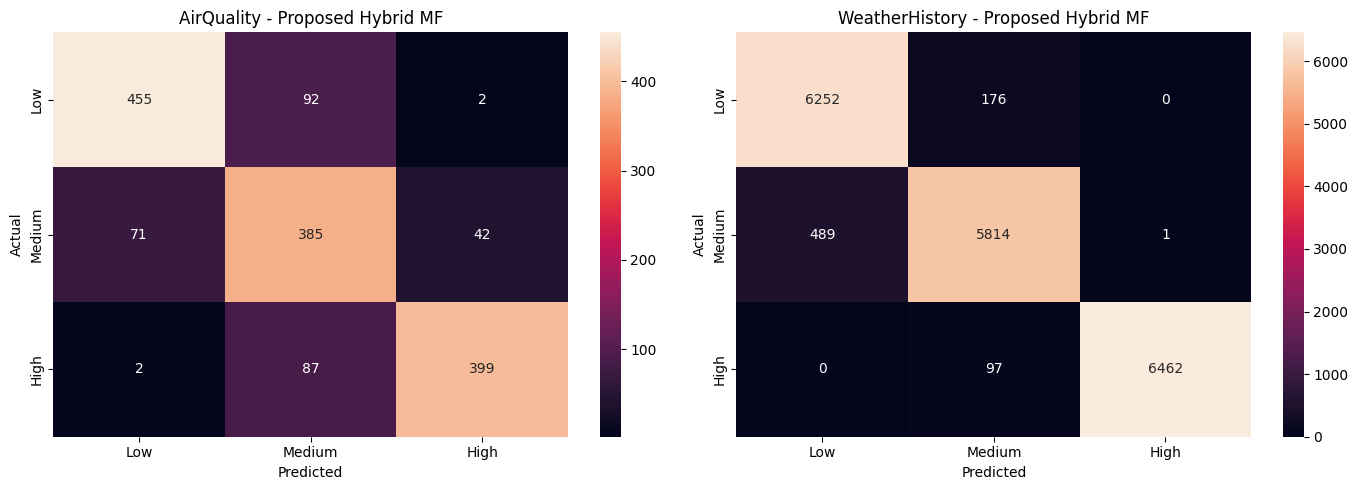

In [ ]:
# ============================================================
# CELL 23: CONFUSION MATRICES
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)


cm_air = confusion_matrix(
    y_test_air,
    air_predictions_proposed
)

sns.heatmap(
    cm_air,
    annot=True,
    fmt="d",
    ax=axes[0],
    xticklabels=[
        "Low",
        "Medium",
        "High"
    ],
    yticklabels=[
        "Low",
        "Medium",
        "High"
    ]
)

axes[0].set_title(
    "AirQuality - Proposed Hybrid MF"
)

axes[0].set_xlabel(
    "Predicted"
)

axes[0].set_ylabel(
    "Actual"
)


cm_weather = confusion_matrix(
    y_test_weather,
    weather_predictions_proposed
)

sns.heatmap(
    cm_weather,
    annot=True,
    fmt="d",
    ax=axes[1],
    xticklabels=[
        "Low",
        "Medium",
        "High"
    ],
    yticklabels=[
        "Low",
        "Medium",
        "High"
    ]
)

axes[1].set_title(
    "WeatherHistory - Proposed Hybrid MF"
)

axes[1].set_xlabel(
    "Predicted"
)

axes[1].set_ylabel(
    "Actual"
)


plt.tight_layout()
plt.show()

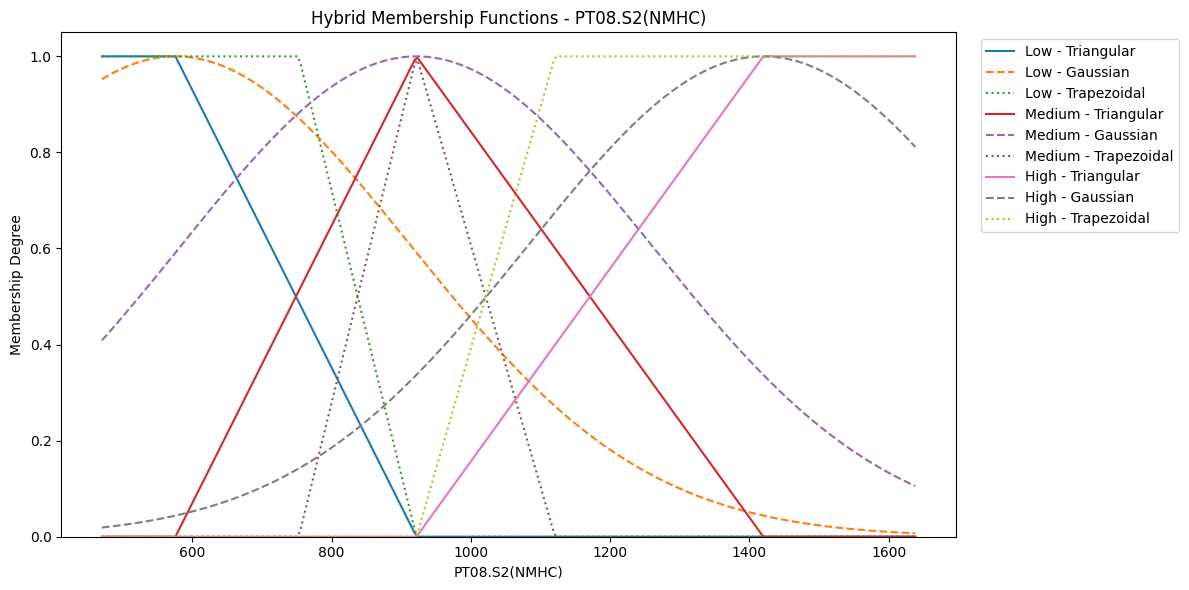

In [ ]:
# ============================================================
# CELL 24: MEMBERSHIP FUNCTION VISUALIZATION
# ============================================================

feature = X_train_air.columns[0]

params = air_parameters[
    feature
]

values = X_train_air[
    feature
].values

x_min = np.percentile(
    values,
    1
)

x_max = np.percentile(
    values,
    99
)

x_values = np.linspace(
    x_min,
    x_max,
    300
)


plt.figure(
    figsize=(12, 6)
)


for term in [
    "Low",
    "Medium",
    "High"
]:

    tri_values = []

    gauss_values = []

    trap_values = []

    for x in x_values:

        p = params[
            term
        ]

        tri_values.append(
            triangular_mf(
                x,
                *p["tri"]
            )
        )

        gauss_values.append(
            gaussian_mf(
                x,
                *p["gauss"]
            )
        )

        trap_values.append(
            trapezoidal_mf(
                x,
                *p["trap"]
            )
        )

    plt.plot(
        x_values,
        tri_values,
        label=f"{term} - Triangular"
    )

    plt.plot(
        x_values,
        gauss_values,
        linestyle="--",
        label=f"{term} - Gaussian"
    )

    plt.plot(
        x_values,
        trap_values,
        linestyle=":",
        label=f"{term} - Trapezoidal"
    )


plt.title(
    f"Hybrid Membership Functions - {feature}"
)

plt.xlabel(
    feature
)

plt.ylabel(
    "Membership Degree"
)

plt.ylim(
    0,
    1.05
)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# CELL 25: FINAL PROJECT TABLE
# ============================================================

final_results = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "Weighted F1",
        "Consistency",
        "Completeness",
        "Fuzzy Rules"
    ],

    "Baseline - Triangular": [
        88.13,
        90.32,
        88.13,
        88.26,
        100.00,
        60.49,
        98
    ],

    "Proposed - Hybrid": [
        combined_accuracy_proposed * 100,
        combined_precision_proposed * 100,
        combined_recall_proposed * 100,
        combined_f1_proposed * 100,
        combined_consistency_proposed,
        combined_completeness_proposed,
        combined_rules_proposed
    ]
})


print(
    final_results.to_string(
        index=False,
        formatters={
            "Baseline - Triangular":
                lambda x: f"{x:.2f}" if isinstance(x, float) else str(x),

            "Proposed - Hybrid":
                lambda x: f"{x:.2f}" if isinstance(x, float) else str(x)
        }
    )
)

      Metric Baseline - Triangular Proposed - Hybrid
    Accuracy                 88.13             94.92
   Precision                 90.32             95.04
      Recall                 88.13             94.92
 Weighted F1                 88.26             94.94
 Consistency                100.00            100.00
Completeness                 60.49             67.28
 Fuzzy Rules                 98.00            109.00


In [ ]:
# ============================================================
# CELL 25: FINAL PROJECT TABLE
# ============================================================

final_results = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "Weighted F1",
        "Consistency",
        "Completeness",
        "Fuzzy Rules"
    ],

    "Baseline - Triangular": [
        88.13,
        90.32,
        88.13,
        88.26,
        100.00,
        60.49,
        98
    ],

    "Proposed - Hybrid": [
        combined_accuracy_proposed * 100,
        combined_precision_proposed * 100,
        combined_recall_proposed * 100,
        combined_f1_proposed * 100,
        combined_consistency_proposed,
        combined_completeness_proposed,
        combined_rules_proposed
    ]
})


print(
    final_results.to_string(
        index=False,
        formatters={
            "Baseline - Triangular":
                lambda x: f"{x:.2f}" if isinstance(x, float) else str(x),

            "Proposed - Hybrid":
                lambda x: f"{x:.2f}" if isinstance(x, float) else str(x)
        }
    )
)

      Metric Baseline - Triangular Proposed - Hybrid
    Accuracy                 88.13             94.92
   Precision                 90.32             95.04
      Recall                 88.13             94.92
 Weighted F1                 88.26             94.94
 Consistency                100.00            100.00
Completeness                 60.49             67.28
 Fuzzy Rules                 98.00            109.00
